# Ensemble v3: saubere Eigenmodelle + öffentliche OOF-Bibliotheken

**Was dein letzter Lauf gezeigt hat:** Der Pool enthielt auch Modelle aus exp005/exp006 (`xgb_fs05` bekam sogar das größte Gewicht). Diese Modelle haben eine zu optimistische CV (exp005: CV 0.9612 → LB 0.9602), das Stacking belohnt genau das. Ergebnis: gleiche CV wie exp007, aber schlechtere LB (0.96081 statt 0.96092).

**Neu in v2**
1. **Eigene Modelle nur aus dem sauberen Setup** (`OWN_INCLUDE = ["fs07"]`), Debug-Läufe raus.
2. **Öffentliche OOF-Bibliotheken** aus einem Ordner einlesen (`EXTERNAL_DIR`), mit Längen-/Reihenfolgen-Check (falsche Zeilenreihenfolge erkennt man an AUC ≈ 0.5).
3. **Duplikate entfernen** (Korrelation ≈ 1.0 mit einem bereits behaltenen Mitglied).
4. **Stacking-Stärke `C` wird gewählt** (bei vielen Mitgliedern braucht Logistic Regression starke Regularisierung).
5. Prüfung, **was die externen Mitglieder wirklich bringen** (nur eigene vs. alle, verschachtelt validiert).
6. Ausgabe weiterhin **als Wahrscheinlichkeiten** (0..1).

Deine Projektdateien bleiben unangetastet: gelesen wird aus `Models/` und `EXTERNAL_DIR`, geschrieben nur nach `Results/submissions/`.

**Neu in v3 (Loader für echte öffentliche Bibliotheken):**
- Dateien mit `id`-Spalte werden **per `id`** an `train.csv`/`test.csv` ausgerichtet (nicht jede öffentliche Datei liegt in Zeilenreihenfolge vor).
- `.npz`-Dateien mit `oof`/`test` (z. B. sachith7), `.parquet`, `.csv`, `.npy`; mehrere Spalten pro Datei = mehrere Mitglieder; Modellnamen enthalten den Ordnernamen (keine Namenskollisionen).
- **Label-Schutz:** OOF-Spalten mit AUC > 0.995 (z. B. versehentlich mitgelieferte Zielspalte) werden ausgeschlossen.
- Optional: **Leave-one-source-out** (`SOURCE_ABLATION`), was jede Quelle dem Stack bringt.

In [1]:
import os, sys, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

_p = Path.cwd().resolve()
for _cand in [_p, *_p.parents]:
    if (_cand / "src").is_dir():
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Ordner 'src' nicht gefunden – Notebook im Projektordner starten.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from src import config as cfg
print("Projektordner:", ROOT)

Projektordner: /home/cgd16/Desktop/Projekte/04 - Kaggle/Playground_Series_Season_6_Episode_10_Predicting_Airline_Satisfaction


## Einstellungen

In [2]:
# --- Eigene Modelle ---
OWN_INCLUDE = ["fs07"]            # nur Modelle, deren Name eines dieser Teilstrings enthaelt ([] = alle)
OWN_EXCLUDE = ["_dbg"]            # Namen mit diesen Teilstrings werden ignoriert
EXTRA = [                         # virtuelle Modelle aus Fold-Checkpoints (nur gute Seeds)
    dict(name="lgbm_fs07_noOrigRows_goodseeds", folder="lgbm_fs07_noOrigRows", model="lgbm",
         seeds=[2, 8, 10, 42, 46, 2026], K=10),
]

# --- Oeffentliche OOF-Bibliotheken ---
EXTERNAL_DIR = None               # z. B. ROOT / "Models" / "external"   (None = keine externen Modelle)
EXTERNAL_PREFIX = "ext_"
LABEL_AUC = 0.995                 # OOF-Spalten mit hoeherer AUC gelten als Label-Leak und werden ausgeschlossen

# --- Auswahl ---
MIN_AUC = 0.90                    # darunter: Zeilenreihenfolge/Format verdaechtig -> ausgeschlossen
MAX_DROP = 0.006                  # EXTERNE Modelle, die mehr als so viel unter dem besten liegen, entfallen
MAX_DROP_OWN = 0.002              # EIGENE Modelle: strenger (faengt defekte Laeufe wie LGBM mit schlechten Seeds ab)
DEDUP_CORR = 0.9999               # Korrelation der Logits, ab der ein Mitglied als Duplikat gilt
EXCLUDE = []                      # zusaetzlich von Hand ausschliessen (exakte Namen)

# --- Validierung / Stacking ---
OUTER_SPLITS = 5
OUTER_SEED = 777
C_GRID = [0.003, 0.03, 0.3, 3.0]  # Kandidaten fuer die Regularisierung des Stackings
HC_ITERS = 30
HC_SUB = 200_000
SOURCE_ABLATION = False           # Leave-one-source-out (langsam bei vielen Mitgliedern)
RUN_HILL = True                   # Hill-Climbing (bei > 40 Mitgliedern langsam)
MIN_GAIN = 2e-5
WRITE = True

## 1) Daten & Vorhersagen einsammeln

In [3]:
_tr = pd.read_csv(cfg.DATA_DIR / cfg.TRAIN_FILE, usecols=[cfg.ID_COL, cfg.TARGET])
_t = _tr[cfg.TARGET]
train_ids = _tr[cfg.ID_COL].values
y = (_t.astype(int) if pd.api.types.is_numeric_dtype(_t)
     else _t.astype(str).str.strip().str.lower().eq("satisfied").astype(int)).values
test_ids = pd.read_csv(cfg.DATA_DIR / cfg.TEST_FILE, usecols=[cfg.ID_COL])[cfg.ID_COL].values
sample_sub = pd.read_csv(cfg.DATA_DIR / cfg.SAMPLE_SUB_FILE)
N_TRAIN, N_TEST = len(y), len(test_ids)
print(f"Train {N_TRAIN} | Test {N_TEST} | Basisrate {y.mean():.4f}")

POOL, INFO = {}, []

def add_model(name, oof, te, source, group, src=None):
    oof = np.asarray(oof, dtype=np.float32).ravel(); te = np.asarray(te, dtype=np.float32).ravel()
    src = src or group
    if len(oof) != N_TRAIN or len(te) != N_TEST or not (np.isfinite(oof).all() and np.isfinite(te).all()):
        INFO.append(dict(name=name, group=group, src=src, source=source, status="uebersprungen (Laenge/NaN)", auc=np.nan)); return
    auc = roc_auc_score(y, oof)
    if auc < MIN_AUC:
        INFO.append(dict(name=name, group=group, src=src, source=source, status=f"verdaechtig (AUC {auc:.3f}) - Reihenfolge/Format?", auc=auc)); return
    if auc > LABEL_AUC:
        INFO.append(dict(name=name, group=group, src=src, source=source, status=f"verdaechtig (AUC {auc:.4f}) - Label-Leak?", auc=auc)); return
    POOL[name] = dict(oof=oof, test=te, group=group, src=src)
    INFO.append(dict(name=name, group=group, src=src, source=source, status="ok", auc=auc))

# a) eigene oof_/test_-Paare
for f in sorted(cfg.MODELS_DIR.glob("oof_*.npy")):
    name = f.stem[len("oof_"):]
    if (OWN_INCLUDE and not any(s in name for s in OWN_INCLUDE)) or any(s in name for s in OWN_EXCLUDE):
        INFO.append(dict(name=name, group="eigen", source="Datei", status="gefiltert (OWN_INCLUDE/EXCLUDE)", auc=np.nan)); continue
    tf = cfg.MODELS_DIR / f"test_{name}.npy"
    if not tf.exists():
        INFO.append(dict(name=name, group="eigen", source="Datei", status="test-Datei fehlt", auc=np.nan)); continue
    add_model(name, np.load(f), np.load(tf), "Datei", "eigen")

# b) virtuelle Modelle aus Checkpoints
for ex in EXTRA:
    d = cfg.MODELS_DIR / "saved_models" / ex["folder"]
    if not d.exists():
        print(f"[EXTRA] Ordner fehlt, uebersprungen: {d.name}"); continue
    oof = np.zeros(N_TRAIN); te = np.zeros(N_TEST); missing = 0
    for seed in ex["seeds"]:
        for fold, (tr, va) in enumerate(StratifiedKFold(ex["K"], shuffle=True, random_state=seed).split(y, y), 1):
            fv = d / f"pred_va_{ex['model']}_seed{seed}_fold{fold}.npy"
            ft = d / f"pred_te_{ex['model']}_seed{seed}_fold{fold}.npy"
            if not (fv.exists() and ft.exists()):
                missing += 1; continue
            oof[va] += np.load(fv) / len(ex["seeds"]); te += np.load(ft) / (ex["K"] * len(ex["seeds"]))
    if missing:
        print(f"[EXTRA] {ex['name']}: {missing} Fold-Dateien fehlen, uebersprungen"); continue
    add_model(ex["name"], oof, te, "Checkpoints", "eigen")

Train 699635 | Test 299844 | Basisrate 0.4436


In [4]:
# c) oeffentliche OOF-Bibliotheken: Ausrichtung per id, npz/npy/csv/parquet, mehrere Spalten moeglich
def _read_any(f):
    if f.suffix == ".npy":
        a = np.load(f)
        a = a.reshape(len(a), -1) if a.ndim == 1 else a
        if a.shape[1] == 2:                       # Wahrscheinlichkeiten beider Klassen -> positive Klasse
            a = a[:, [1]]
        return pd.DataFrame(a, columns=[f"c{i}" for i in range(a.shape[1])])
    return pd.read_parquet(f) if f.suffix == ".parquet" else pd.read_csv(f)

def _align(df, ids, what):
    if "id" in df.columns:
        d = df.drop_duplicates("id").set_index("id")
        try:
            return d.loc[ids]
        except KeyError:
            raise ValueError(f"{what}: ids passen nicht zu train/test")
    if len(df) != len(ids):
        raise ValueError(f"{what}: Laenge {len(df)} != {len(ids)}")
    return df.reset_index(drop=True)

def _numeric(df):
    df = df.drop(columns=[c for c in df.columns if str(c).lower() in ("id", "index", "fold")], errors="ignore")
    return df.select_dtypes(include=[np.number])

def _add_pair(tag, src_name, o_raw, t_raw, source):
    o = _numeric(_align(o_raw, train_ids, "oof")); t = _numeric(_align(t_raw, test_ids, "test"))
    common = [c for c in o.columns if c in t.columns]
    if common:
        pairs = [(c, c) for c in common]
    elif o.shape[1] == 1 and t.shape[1] == 1:
        pairs = [(o.columns[0], t.columns[0])]
    else:
        INFO.append(dict(name=EXTERNAL_PREFIX + tag, group="extern", src=src_name, source=source,
                         status="Spalten passen nicht zusammen", auc=np.nan)); return 0
    for co, ct in pairs:
        nm = EXTERNAL_PREFIX + tag + ("" if len(pairs) == 1 else f"__{co}")
        add_model(nm, o[co].values, t[ct].values, source, "extern", src=src_name)
    return len(pairs)

def load_external(folder):
    folder = Path(folder)
    files = [f for f in sorted(folder.rglob("*")) if f.is_file()]
    n_files = n_members = 0
    for f in files:                                  # npz mit 'oof' und 'test'
        if f.suffix == ".npz":
            z = np.load(f)
            if "oof" in z.files and "test" in z.files:
                add_model(EXTERNAL_PREFIX + f"{f.parent.name}_{f.stem}", z["oof"], z["test"], f.name, "extern", src=f.parent.name)
                n_files += 1
    tab = [f for f in files if f.suffix in (".npy", ".csv", ".parquet")]
    for f in tab:                                    # Paare 'oof' <-> 'test'
        if "oof" not in f.stem.lower():
            continue
        tname = re.sub("oof", "test", f.stem, flags=re.I)
        tf = next((g for g in tab if g.parent == f.parent and g.stem == tname), None)
        tag = f"{f.parent.name}_{f.stem}"
        if tf is None:
            INFO.append(dict(name=EXTERNAL_PREFIX + tag, group="extern", src=f.parent.name, source=f.name,
                             status="test-Datei fehlt", auc=np.nan)); continue
        try:
            n_members += _add_pair(tag, f.parent.name, _read_any(f), _read_any(tf), f.name); n_files += 1
        except Exception as e:
            INFO.append(dict(name=EXTERNAL_PREFIX + tag, group="extern", src=f.parent.name, source=f.name,
                             status=f"Lesefehler: {type(e).__name__}: {str(e)[:60]}", auc=np.nan))
    print(f"Externe Dateien/Paare gelesen: {n_files}")

if EXTERNAL_DIR is not None:
    load_external(EXTERNAL_DIR)
else:
    print("EXTERNAL_DIR = None -> nur eigene Modelle")

info = pd.DataFrame(INFO).set_index("name").sort_values("auc", ascending=False)
pd.set_option("display.max_rows", 300, "display.width", 220)
display(info.round(6))
print(info["status"].str.split(" ").str[0].value_counts().to_string())


EXTERNAL_DIR = None -> nur eigene Modelle


,group,source,status,auc,src
name,,,,,
xgb_fs07_noOrigRows_s42-2026-10-23-16-2-8-46,eigen,Datei,ok,0.961248,eigen
lgbm_fs07_noOrigRows_goodseeds,eigen,Checkpoints,ok,0.961239,eigen
cat_fs07_noOrigRows_s42-2026-10-23-16-2-8-46,eigen,Datei,ok,0.961110,eigen
lgbm_fs07_noOrigRows_s42-2026-10-23-16-2-8-46,eigen,Datei,ok,0.957120,eigen
cat_fs05_s42-2026-10-23-16-2-8-46,eigen,Datei,gefiltert (OWN_INCLUDE/EXCLUDE),NaN,NaN
cat_fs06_s42-2026-10-23-16-2-8-46,eigen,Datei,gefiltert (OWN_INCLUDE/EXCLUDE),NaN,NaN
lgbm_fs05_s42-2026-10-23-16-2-8-46,eigen,Datei,gefiltert (OWN_INCLUDE/EXCLUDE),NaN,NaN
lgbm_fs06_s42-2026-10-23-16-2-8-46,eigen,Datei,gefiltert (OWN_INCLUDE/EXCLUDE),NaN,NaN
lgbm_fs07_noOrigRows_dbg_s42,eigen,Datei,gefiltert (OWN_INCLUDE/EXCLUDE),NaN,NaN


status
gefiltert    7
ok           4


In [5]:
# Auswahl: zu schwache raus, dann Duplikate entfernen (bessere Mitglieder zuerst behalten)
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

best = info.loc[list(POOL), "auc"].max()
weak = [n for n in POOL if best - info.loc[n, "auc"] > (MAX_DROP_OWN if POOL[n]["group"] == "eigen" else MAX_DROP)]
cand = sorted([n for n in POOL if n not in weak and n not in EXCLUDE], key=lambda n: -info.loc[n, "auc"])
if weak: print(f"Ausgeschlossen (zu weit unter dem besten; eigen > {MAX_DROP_OWN}, extern > {MAX_DROP}): {weak}")

rng = np.random.default_rng(0)
sub = rng.choice(N_TRAIN, size=min(150_000, N_TRAIN), replace=False)
Zs = {n: logit(POOL[n]["oof"][sub].astype(np.float64)) for n in cand}
sel, dups = [], []
for n in cand:
    dup_of = next((k for k in sel if np.corrcoef(Zs[n], Zs[k])[0, 1] > DEDUP_CORR), None)
    (dups.append((n, dup_of)) if dup_of else sel.append(n))
for n, k in dups: print(f"Duplikat entfernt: {n}  (≈ {k})")
print(f"\n{len(sel)} Mitglieder im Pool ({sum(POOL[n]['group']=='eigen' for n in sel)} eigene, "
      f"{sum(POOL[n]['group']=='extern' for n in sel)} externe)")

P = np.column_stack([POOL[n]["oof"] for n in sel]).astype(np.float32)
PT = np.column_stack([POOL[n]["test"] for n in sel]).astype(np.float32)
M = P.shape[1]
assert M >= 2, "Mindestens 2 Mitglieder noetig"
is_ext = np.array([POOL[n]["group"] == "extern" for n in sel])
SRC = {n: POOL[n].get("src", POOL[n]["group"]) for n in sel}


Ausgeschlossen (zu weit unter dem besten; eigen > 0.002, extern > 0.006): ['lgbm_fs07_noOrigRows_s42-2026-10-23-16-2-8-46']

3 Mitglieder im Pool (3 eigene, 0 externe)


## 2) Ähnlichkeit der Mitglieder

Korrelation der Logits: min 0.9985 | Mittel 0.9990 | max 0.9996


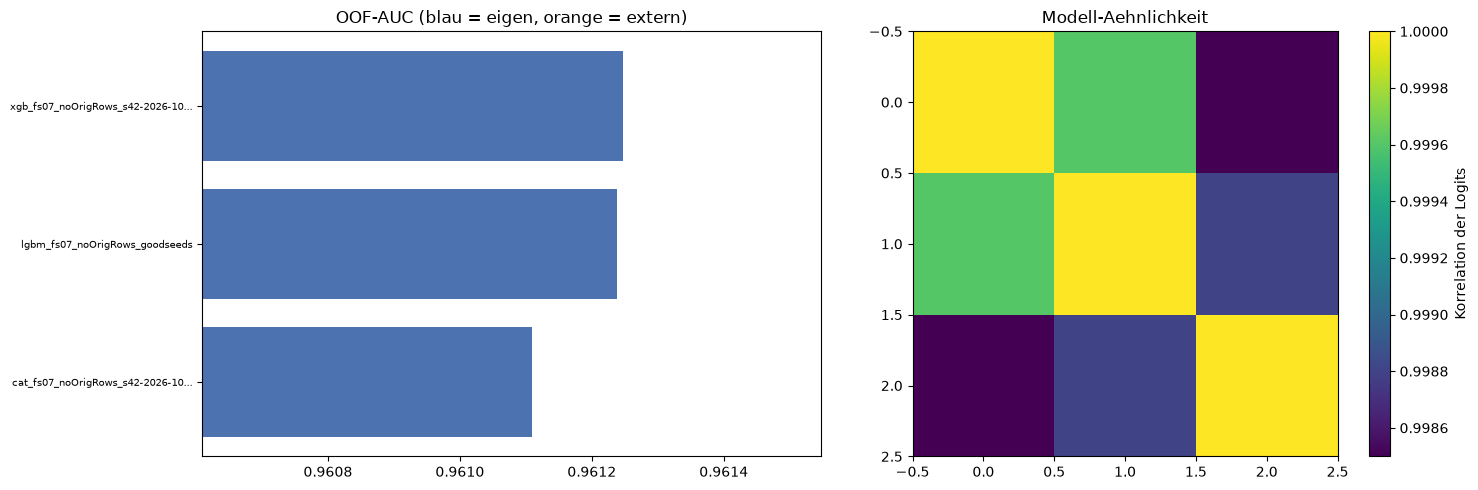

In [6]:
Z_sub = np.column_stack([Zs[n] for n in sel])
C = np.corrcoef(Z_sub.T)
off = C[np.triu_indices(M, 1)]
print(f"Korrelation der Logits: min {off.min():.4f} | Mittel {off.mean():.4f} | max {off.max():.4f}")
if is_ext.any() and (~is_ext).any():
    cross = C[np.ix_(~is_ext, is_ext)]
    within = C[np.ix_(~is_ext, ~is_ext)][np.triu_indices((~is_ext).sum(), 1)]
    print(f"Eigen<->Extern: Mittel {cross.mean():.4f} | Eigen<->Eigen: Mittel {within.mean():.4f}   "
          "(niedriger = mehr Vielfalt)")

short = [(n if len(n) <= 34 else n[:31] + "...") for n in sel]
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.28 * M + 3)))
a = info.loc[sel, "auc"].values[::-1]
axes[0].barh(short[::-1], a, color=["#dd8452" if e else "#4c72b0" for e in is_ext[::-1]])
axes[0].set_xlim(a.min() - 0.0005, a.max() + 0.0003); axes[0].set_title("OOF-AUC (blau = eigen, orange = extern)")
im = axes[1].imshow(C, vmin=C.min(), vmax=1, cmap="viridis"); plt.colorbar(im, ax=axes[1], label="Korrelation der Logits")
axes[1].set_title("Modell-Aehnlichkeit")
if M <= 40:
    axes[0].tick_params(axis="y", labelsize=7)
else:
    axes[0].set_yticks([])
plt.tight_layout(); plt.show()

## 3) Methoden im Vergleich (verschachtelte Validierung)
Neu: `lr_stack` wählt seine Regularisierung `C` selbst (auf einem Teil der Trainingszeilen der jeweiligen Außen-Fold), `lr_stack_C1` ist die feste Variante mit C = 1.

In [7]:
class LinearModel:
    def __init__(self, w, b=0.0, space="logit"):
        self.w, self.b, self.space = np.asarray(w, float), float(b), space
    def _Z(self, P): return logit(P.astype(np.float64)) if self.space == "logit" else P.astype(np.float64)
    def score(self, P): return self._Z(P) @ self.w + self.b
    def proba(self, P):
        s = self.score(P)
        return sigmoid(s) if self.space == "logit" else np.clip(s, 0, 1)

class RankModel:
    def __init__(self, w): self.w = np.asarray(w, float)
    def score(self, P): return np.column_stack([rankdata(P[:, j]) / len(P) for j in range(P.shape[1])]) @ self.w
    proba = None

CHOSEN_C = []

def fit_equal(space):
    return lambda P, y_: (RankModel(np.ones(P.shape[1]) / P.shape[1]) if space == "rank"
                          else LinearModel(np.ones(P.shape[1]) / P.shape[1], 0.0, space))

def fit_best_single(P, y_):
    idx = np.random.default_rng(1).choice(len(y_), size=min(len(y_), 200_000), replace=False)
    a = [roc_auc_score(y_[idx], P[idx, j]) for j in range(P.shape[1])]
    w = np.zeros(P.shape[1]); w[int(np.argmax(a))] = 1.0
    return LinearModel(w, 0.0, "logit")

def fit_nnls(P, y_):
    Z = logit(P.astype(np.float64)); m = Z.shape[1]
    def f(th):
        w, b = th[:m], th[m]
        z = Z @ w + b
        g = sigmoid(z) - y_
        return np.mean(np.logaddexp(0, z) - y_ * z), np.r_[Z.T @ g / len(y_), g.mean()]
    res = minimize(f, np.r_[np.ones(m) / m, 0.0], jac=True, method="L-BFGS-B",
                   bounds=[(0, None)] * m + [(None, None)])
    return LinearModel(res.x[:m], res.x[m], "logit")

def _lr(Z, y_, C):
    lr = LogisticRegression(C=C, max_iter=300).fit(Z, y_)
    return LinearModel(lr.coef_[0], lr.intercept_[0], "logit")

def fit_lr_c1(P, y_):
    return _lr(logit(P.astype(np.float64)), y_, 1.0)

def fit_lr_auto(P, y_):
    Z = logit(P.astype(np.float64))
    perm = np.random.default_rng(3).permutation(len(y_)); cut = int(0.8 * len(y_))
    a, b = perm[:cut], perm[cut:]
    sc = {C_: roc_auc_score(y_[b], _lr(Z[a], y_[a], C_).score(P[b])) for C_ in C_GRID}
    bestC = max(sc, key=sc.get); CHOSEN_C.append(bestC)
    return _lr(Z, y_, bestC)

def fit_hill(P, y_, iters=HC_ITERS, sub_n=HC_SUB):
    Z = logit(P.astype(np.float64)); m = Z.shape[1]
    idx = np.random.default_rng(2).choice(len(y_), size=min(len(y_), sub_n), replace=False)
    Zs_, ys = Z[idx], y_[idx]
    counts, cur, k = np.zeros(m), np.zeros(len(ys)), 0
    best_auc, best_counts, stall = -1.0, counts.copy(), 0
    for _ in range(iters):
        sc = [roc_auc_score(ys, (cur + Zs_[:, j]) / (k + 1)) for j in range(m)]
        j = int(np.argmax(sc)); counts[j] += 1; cur += Zs_[:, j]; k += 1
        if sc[j] > best_auc + 1e-7: best_auc, best_counts, stall = sc[j], counts.copy(), 0
        else:
            stall += 1
            if stall >= 4: break
    return LinearModel(best_counts / best_counts.sum(), 0.0, "logit")

METHODS = {"equal_prob": fit_equal("prob"), "equal_logit": fit_equal("logit"), "equal_rank": fit_equal("rank"),
           "best_single": fit_best_single, "nnls_logloss": fit_nnls,
           "lr_stack_C1": fit_lr_c1, "lr_stack": fit_lr_auto}
if RUN_HILL and M <= 40:
    METHODS["hill_climb"] = fit_hill
elif RUN_HILL:
    print(f"Hill-Climbing uebersprungen ({M} Mitglieder > 40) - RUN_HILL/Grenze bei Bedarf anpassen")

def nested(methods, P_, label=""):
    t0 = time.time(); out = {k: [] for k in methods}
    for i, (tr, va) in enumerate(StratifiedKFold(OUTER_SPLITS, shuffle=True, random_state=OUTER_SEED).split(P_, y), 1):
        for name, fit in methods.items():
            out[name].append(roc_auc_score(y[va], fit(P_[tr], y[tr]).score(P_[va])))
        print(f"{label}Fold {i}/{OUTER_SPLITS} fertig ({time.time() - t0:.0f}s)")
    return out

fold_auc = nested(METHODS, P)
base = np.array(fold_auc["equal_logit"])
res = pd.DataFrame([dict(methode=n, auc_mean=np.mean(a), auc_std=np.std(a, ddof=1),
                         delta_vs_equal_logit=(np.array(a) - base).mean(), folds_besser=int((np.array(a) > base).sum()),
                         wahrscheinlichkeit="ja" if n != "equal_rank" else "nein (Raenge)")
                    for n, a in fold_auc.items()]).set_index("methode").sort_values("auc_mean", ascending=False)
try:
    display(res.style.format({"auc_mean": "{:.6f}", "auc_std": "{:.6f}", "delta_vs_equal_logit": "{:+.6f}"}))
except Exception:
    display(res.round(6))
print(f"Bestes Einzelmitglied (OOF, ohne Validierung): {info.loc[sel[0], 'auc']:.6f}")
if CHOSEN_C:
    print("Gewaehlte Regularisierung C je Außen-Fold:", CHOSEN_C)

Fold 1/5 fertig (3s)
Fold 2/5 fertig (6s)
Fold 3/5 fertig (8s)
Fold 4/5 fertig (11s)
Fold 5/5 fertig (14s)


,auc_mean,auc_std,delta_vs_equal_logit,folds_besser,wahrscheinlichkeit
methode,,,,,
equal_rank,0.961296,0.000758,0.000002,4,nein (Raenge)
nnls_logloss,0.961295,0.000756,0.000001,3,ja
equal_logit,0.961294,0.000757,0.000000,0,ja
equal_prob,0.961294,0.000756,-0.000000,1,ja
lr_stack_C1,0.961292,0.000757,-0.000002,4,ja
lr_stack,0.961292,0.000757,-0.000002,4,ja
hill_climb,0.961290,0.000755,-0.000004,1,ja
best_single,0.961240,0.000757,-0.000054,0,ja


Bestes Einzelmitglied (OOF, ohne Validierung): 0.961248
Gewaehlte Regularisierung C je Außen-Fold: [3.0, 3.0, 0.03, 0.003, 0.003]


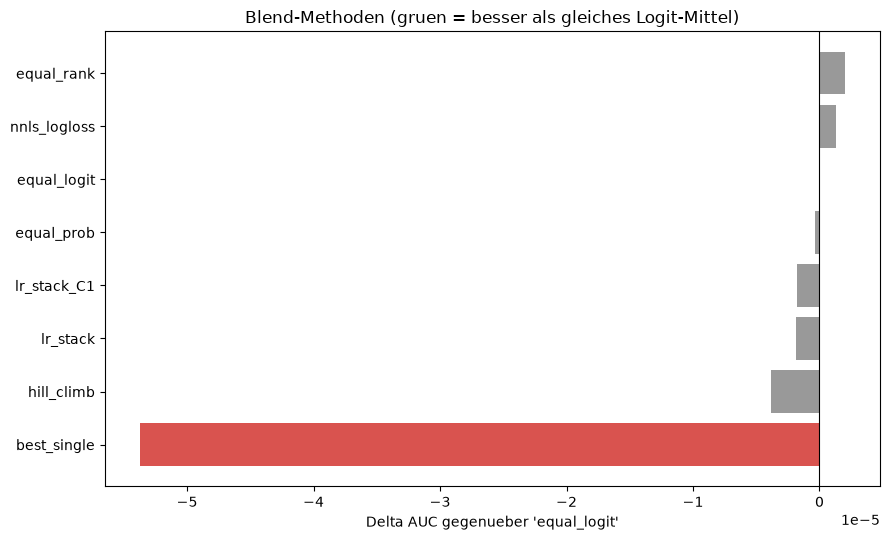

In [8]:
r = res.sort_values("delta_vs_equal_logit")
col = ["#5cb85c" if v > MIN_GAIN else ("#d9534f" if v < -MIN_GAIN else "#999999") for v in r["delta_vs_equal_logit"]]
fig, ax = plt.subplots(figsize=(9, 0.5 * len(r) + 1.5))
ax.barh(r.index, r["delta_vs_equal_logit"], color=col); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Delta AUC gegenueber 'equal_logit'"); ax.set_title("Blend-Methoden (gruen = besser als gleiches Logit-Mittel)")
plt.tight_layout(); plt.show()

## 4) Was bringt welche Gruppe wirklich?
Gleiche Methode (`lr_stack` mit fest gewähltem `C`), gleiche Außen-Folds, drei Mitgliedermengen: **nur eigene**, **nur extern**, **alle**. Der Gewinn je Gruppe zeigt, ob sich das Einbinden lohnt – nur Gewinne, die **in fast allen Folds** sichtbar sind, zählen. Mit `SOURCE_ABLATION = True` wird zusätzlich jede Quelle einzeln weggelassen (dauert deutlich länger).

In [9]:
C_FIX = float(pd.Series(CHOSEN_C).mode().iloc[0]) if CHOSEN_C else 0.03
def fit_lr_fixed(P_, y_): return _lr(logit(P_.astype(np.float64)), y_, C_FIX)
print(f"Feste Regularisierung fuer die Vergleiche: C = {C_FIX}")

sets = {"alle": np.ones(M, bool)}
if is_ext.any() and (~is_ext).sum() >= 2:
    sets["nur eigene"], sets["nur extern"] = ~is_ext, is_ext
if len(sets) > 1:
    r = {k: np.array(nested({"lr": fit_lr_fixed}, P[:, m], label=f"[{k}] ")["lr"]) for k, m in sets.items()}
    for k, a in r.items(): print(f"{k:12s} {a.mean():.6f}  ({sets[k].sum()} Mitglieder)")
    d1, d2 = r["alle"] - r["nur eigene"], r["alle"] - r["nur extern"]
    print(f"\nGewinn durch EXTERNE Mitglieder (alle - nur eigene): {d1.mean():+.6f} | in {int((d1 > 0).sum())}/{OUTER_SPLITS} Folds besser")
    print(f"Gewinn durch EIGENE Mitglieder  (alle - nur extern) : {d2.mean():+.6f} | in {int((d2 > 0).sum())}/{OUTER_SPLITS} Folds besser")
    print("Delta je Fold (extern):", np.round(d1 * 1e4, 2), "(x1e-4)")
else:
    print("Keine externen Mitglieder im Pool - Abschnitt uebersprungen.")

if SOURCE_ABLATION and len(set(SRC.values())) > 1:
    full = np.array(nested({"lr": fit_lr_fixed}, P, label="[alle] ")["lr"]).mean()
    rows = []
    for s_ in sorted(set(SRC.values())):
        mask = np.array([SRC[n] != s_ for n in sel])
        if mask.sum() < 2: continue
        a = np.array(nested({"lr": fit_lr_fixed}, P[:, mask], label=f"[ohne {s_}] ")["lr"]).mean()
        rows.append(dict(quelle=s_, mitglieder=int((~mask).sum()), delta_ohne_quelle=a - full))
    display(pd.DataFrame(rows).sort_values("delta_ohne_quelle").set_index("quelle").round(6))
    print("Negativer Wert = der Stack wird ohne diese Quelle schlechter (Quelle traegt).")


Feste Regularisierung fuer die Vergleiche: C = 0.003
Keine externen Mitglieder im Pool - Abschnitt uebersprungen.


## 5) Finale Methode, Gewichte, Submission

In [10]:
cands = res[res.index != "equal_rank"]
top = cands["auc_mean"].idxmax()
gain = cands.loc[top, "auc_mean"] - cands.loc["equal_logit", "auc_mean"]
FINAL = top if gain >= MIN_GAIN else "equal_logit"
print(f"Beste validierte Methode: {top} (Gewinn gegenueber equal_logit: {gain:+.6f}) -> FINAL = {FINAL}")

final_model = METHODS[FINAL](P, y)
w = pd.Series(final_model.w, index=sel).sort_values(ascending=False)
print("\nGroesste Gewichte:"); print(w.head(15).round(4).to_string())
if abs(final_model.b) > 0: print(f"Achsenabschnitt: {final_model.b:+.4f}")
print(f"... Gewicht auf <= 0: {(w <= 1e-9).sum()} von {len(w)} | Summe der Gewichte {w.sum():.3f}")
if is_ext.any():
    print(f"Gewichtsanteil externer Mitglieder (|w|): {np.abs(final_model.w[is_ext]).sum() / np.abs(final_model.w).sum():.1%}")

Beste validierte Methode: nnls_logloss (Gewinn gegenueber equal_logit: +0.000001) -> FINAL = equal_logit

Groesste Gewichte:
xgb_fs07_noOrigRows_s42-2026-10-23-16-2-8-46    0.3333
lgbm_fs07_noOrigRows_goodseeds                  0.3333
cat_fs07_noOrigRows_s42-2026-10-23-16-2-8-46    0.3333
... Gewicht auf <= 0: 0 von 3 | Summe der Gewichte 1.000


In [11]:
from datetime import datetime

def write_sub(method_name, model, nested_auc):
    p = np.clip(model.proba(PT), 0.0, 1.0)
    id_col, target_col = sample_sub.columns[0], sample_sub.columns[1]
    sub = sample_sub.copy()
    sub[target_col] = pd.Series(p, index=test_ids).reindex(sub[id_col].values).values
    assert sub[target_col].notna().all() and len(sub) == N_TEST
    assert sub[target_col].between(0, 1).all()
    assert sub[target_col].nunique() > 10, "Submission wirkt binaer/diskret!"
    cfg.SUBMISSIONS_DIR.mkdir(parents=True, exist_ok=True)
    tag = "stackv2" if is_ext.any() else "own"
    path = cfg.SUBMISSIONS_DIR / f"sub_{datetime.now():%Y%m%d_%H%M}_{tag}_{method_name}_cv{nested_auc:.4f}.csv"
    sub.to_csv(path, index=False)
    print(f"gespeichert: {path.name} | Mittel {p.mean():.4f} | Std {p.std():.4f} | eindeutige Werte {sub[target_col].nunique()}")

oof_p = final_model.proba(P)
print(f"Train-OOF-Blend: Mittel {oof_p.mean():.4f}, Std {oof_p.std():.4f} (Vergleich mit Testwerten unten)")
if WRITE:
    write_sub(FINAL, final_model, res.loc[FINAL, "auc_mean"])
else:
    print("WRITE = False -> keine Datei geschrieben")

Train-OOF-Blend: Mittel 0.4437, Std 0.4329 (Vergleich mit Testwerten unten)
gespeichert: sub_20261013_1924_own_equal_logit_cv0.9613.csv | Mittel 0.4438 | Std 0.4327 | eindeutige Werte 299844


## Lesehilfe
- **Nested CV ≠ Public LB.** Unterschiede um 1e-4 zwischen starken Stacks liegen im Rauschen der Public LB. Wähle die zwei finalen Submissions nach nested CV und nach Verschiedenheit, nicht nach der LB.
- **Gewichtsanteil externer Mitglieder** zeigt, ob sie wirklich genutzt werden. Bei Gewinn < 0.00002 oder gemischten Folds (z. B. 3/5) lohnt sich der Aufwand nicht.
- **Verdächtige Dateien** (AUC < 0.90): meist falsche Zeilenreihenfolge oder ein Format-Problem (z. B. 2-Spalten-Wahrscheinlichkeiten). Prüfe Reihenfolge = `train.csv`/`test.csv`.
- **Gleiche Fold-Aufteilung:** Öffentliche OOFs verwenden meist `StratifiedKFold(5, shuffle=True, random_state=42)`, deine verwenden andere Seeds. Für das Stacking ist das unkritisch (jede Vorhersage ist out-of-fold), ein kleiner Restoptimismus bleibt.
- **Regeln:** Prüfe in den Competition Rules, ob die Nutzung öffentlicher Vorhersagen erlaubt ist, bevor du eine solche Submission auswählst.